# Assignment 8: Matplotlib & Seaborn
## Sleep Health and Lifestyle Analysis
Zaina Hassan


**Dataset:** [Sleep Health and Lifestyle Dataset (Kaggle)](https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset)


# Introduction

This analysis explores relationships between sleep duration, sleep quality, physical activity, and stress using the *Sleep Health and Lifestyle Dataset* (374 records). I chose this topic because everyday habits and well being are personally relevant and lend themselves to meaningful comparisons across numerical and categorical variables.

**Questions:**

(1) How does sleep duration relate to reported sleep quality?

(2) How do average stress levels vary across physical activity groups?

The dataset is  described as synthetic, so the analysis is exploratory and cannot establish causal relationships or population level health effects. The purpose of the assignment is also to compare the plotting workflows and customization options of Matplotlib and Seaborn.

# Data Exploration

The first step is to import the data and inspect its structure, numerical summaries (including mean, median, and quartiles), missingness, and category distributions.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

filename = Path("Sleep_health_and_lifestyle_dataset.csv")
if not filename.exists():
    raise FileNotFoundError(
        f"Could not find {filename.name}. Download the CSV from the Kaggle link "
        "above and upload it to the notebook's working directory."
    )
df = pd.read_csv(filename)
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())
print("Data types:")
df.info()

Dataset shape: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Columns: ['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps', 'Sleep Disorder']
Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate    

In [ ]:
# Numerical summary: count, mean, standard deviation, minimum, quartiles, maximum
summary = df.describe(include="all").T
display(summary)

# Explicitly show medians and quartiles for numeric columns
numeric_summary = df.select_dtypes(include="number").agg(
    ["mean", "median", "min", "max"]
).T
quartiles = df.select_dtypes(include="number").quantile([0.25, 0.75]).T
quartiles.columns = ["Q1 (25%)", "Q3 (75%)"]
display(numeric_summary.join(quartiles).round(2))

missing = df.isna().sum().to_frame("Missing values")
missing["Percent missing"] = (missing["Missing values"] / len(df) * 100).round(1)
display(missing)
print("Duplicate rows:", df.duplicated().sum())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Person ID,374.0,NaN,NaN,NaN,187.5,108.108742,1.0,94.25,187.5,280.75,374.0
Gender,374,2,Male,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,374.0,NaN,NaN,NaN,42.184492,8.673133,27.0,35.25,43.0,50.0,59.0
Occupation,374,11,Nurse,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Duration,374.0,NaN,NaN,NaN,7.132086,0.795657,5.8,6.4,7.2,7.8,8.5
Quality of Sleep,374.0,NaN,NaN,NaN,7.312834,1.196956,4.0,6.0,7.0,8.0,9.0
Physical Activity Level,374.0,NaN,NaN,NaN,59.171123,20.830804,30.0,45.0,60.0,75.0,90.0
Stress Level,374.0,NaN,NaN,NaN,5.385027,1.774526,3.0,4.0,5.0,7.0,8.0
BMI Category,374,4,Normal,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Pressure,374,25,130/85,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,mean,median,min,max,Q1 (25%),Q3 (75%)
Person ID,187.50,187.5,1.0,374.0,94.25,280.75
Age,42.18,43.0,27.0,59.0,35.25,50.00
Sleep Duration,7.13,7.2,5.8,8.5,6.40,7.80
Quality of Sleep,7.31,7.0,4.0,9.0,6.00,8.00
Physical Activity Level,59.17,60.0,30.0,90.0,45.00,75.00
Stress Level,5.39,5.0,3.0,8.0,4.00,7.00
Heart Rate,70.17,70.0,65.0,86.0,68.00,72.00
Daily Steps,6816.84,7000.0,3000.0,10000.0,5600.00,8000.00


,Missing values,Percent missing
Person ID,0,0.0
Gender,0,0.0
Age,0,0.0
Occupation,0,0.0
Sleep Duration,0,0.0
Quality of Sleep,0,0.0
Physical Activity Level,0,0.0
Stress Level,0,0.0
BMI Category,0,0.0
Blood Pressure,0,0.0


Duplicate rows: 0


# Data Wrangling

I standardized column names, remove exact duplicates, convert key variables to numeric, drop rows missing values needed for the plots, and group physical activity into low, moderate, and high categories. I kept the original dataset unchanged in `df` and analyze a cleaned copy.

In [ ]:
clean = df.copy()
clean.columns = (clean.columns.str.strip().str.lower()
                 .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))

needed = ["sleep_duration", "quality_of_sleep", "physical_activity_level", "stress_level"]
missing_cols = sorted(set(needed) - set(clean.columns))
if missing_cols:
    raise ValueError(f"Expected columns not found: {missing_cols}. Check the downloaded CSV.")

initial_rows = len(clean)
clean = clean.drop_duplicates().copy()
for col in needed:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
clean = clean.dropna(subset=needed).copy()

# Activity bands are descriptive thirds of the observed activity-level scale.
# They are not clinical exercise recommendations.
clean["activity_group"] = pd.cut(
    clean["physical_activity_level"],
    bins=[-np.inf, 40, 60, np.inf],
    labels=["Low (≤40)", "Moderate (41–60)", "High (>60)"]
)
print(f"Original rows: {initial_rows}; cleaned rows: {len(clean)}; removed: {initial_rows-len(clean)}")
print("Activity groups:")
display(clean["activity_group"].value_counts().sort_index().to_frame("Count"))
display(clean[needed].describe().round(2))

Original rows: 374; cleaned rows: 374; removed: 0
Activity groups:


,Count
activity_group,
Low (≤40),80
Moderate (41–60),151
High (>60),143


,sleep_duration,quality_of_sleep,physical_activity_level,stress_level
count,374.00,374.00,374.00,374.00
mean,7.13,7.31,59.17,5.39
std,0.80,1.20,20.83,1.77
min,5.80,4.00,30.00,3.00
25%,6.40,6.00,45.00,4.00
50%,7.20,7.00,60.00,5.00
75%,7.80,8.00,75.00,7.00
max,8.50,9.00,90.00,8.00


In [ ]:
# Summary tables used to interpret the visualizations
activity_summary = (clean.groupby("activity_group", observed=True)
                    .agg(mean_stress=("stress_level", "mean"),
                         median_stress=("stress_level", "median"),
                         count=("stress_level", "size"))
                    .reset_index())
display(activity_summary.round(2))

correlation = clean["sleep_duration"].corr(clean["quality_of_sleep"])
print(f"Pearson correlation between sleep duration and sleep quality: {correlation:.3f}")
print("These descriptive associations do not imply causation.")

,activity_group,mean_stress,median_stress,count
0,Low (≤40),5.78,7.0,80
1,Moderate (41–60),5.22,5.0,151
2,High (>60),5.34,5.0,143


Pearson correlation between sleep duration and sleep quality: 0.883
These descriptive associations do not imply causation.


# Visualizations Part 1: Matplotlib

**Plot 1:** Scatterplot of sleep duration versus sleep quality, colored by stress level. Each point represents a record. This visual checks whether longer sleep tends to coincide with higher reported quality and whether stress differs across the pattern.

**Customizations:** figure size, title, axis labels and label sizes, point marker/size/color, colorbar, tick sizes, annotation, and grid styling.

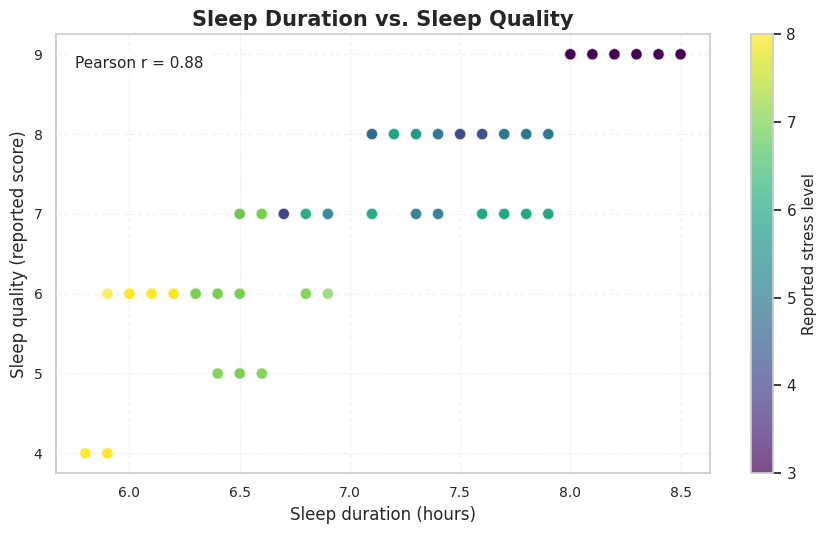

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
points = ax.scatter(clean["sleep_duration"], clean["quality_of_sleep"],
                    c=clean["stress_level"], cmap="viridis", s=65,
                    marker="o", alpha=0.7, edgecolors="white", linewidths=0.5)
bar = fig.colorbar(points, ax=ax)
bar.set_label("Reported stress level", fontsize=11)
ax.set_title("Sleep Duration vs. Sleep Quality", fontsize=15, fontweight="bold")
ax.set_xlabel("Sleep duration (hours)", fontsize=12)
ax.set_ylabel("Sleep quality (reported score)", fontsize=12)
ax.tick_params(labelsize=10)
ax.grid(alpha=0.25, linestyle="--")
ax.annotate(f"Pearson r = {correlation:.2f}", xy=(0.03, 0.95),
            xycoords="axes fraction", va="top", fontsize=11,
            bbox=dict(boxstyle="round", fc="white", alpha=0.85))
plt.tight_layout()
plt.show()

**Plot 2:** Bar chart of mean stress level across activity groups, with sample sizes annotated above bars. This visual compares group averages rather than individual records.

**Customizations:** figure size, bar colors/width, title and axis labels, tick formatting, annotation, grid, and y-axis range.

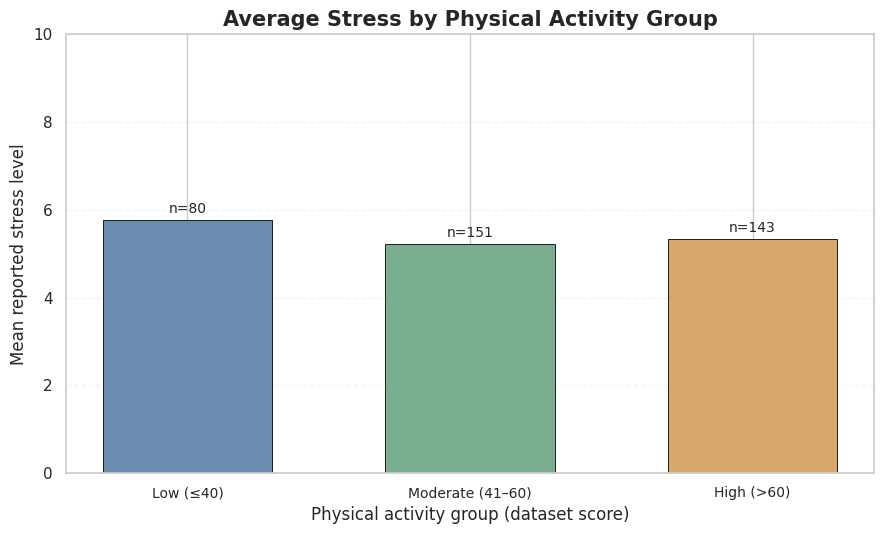

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#6A8CAF", "#7BAE91", "#D7A86E"]
bars = ax.bar(activity_summary["activity_group"].astype(str),
              activity_summary["mean_stress"], color=colors, width=0.6,
              edgecolor="black", linewidth=0.6)
ax.set_title("Average Stress by Physical Activity Group", fontsize=15, fontweight="bold")
ax.set_xlabel("Physical activity group (dataset score)", fontsize=12)
ax.set_ylabel("Mean reported stress level", fontsize=12)
ax.tick_params(axis="x", labelsize=10)
ax.set_ylim(0, max(10, activity_summary["mean_stress"].max() * 1.2))
ax.grid(axis="y", alpha=0.25, linestyle="--")
ax.set_axisbelow(True)
for bar, count in zip(bars, activity_summary["count"]):
    ax.annotate(f"n={count}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

# Visualizations Part 2: Seaborn

These are recreations of the same two visualizations using Seaborn. The first uses a continuous color mapping for stress and the second shows precomputed group means so it matches the Matplotlib chart. Titles, labels, sizes, legends/colorbars, and annotations are customized again.

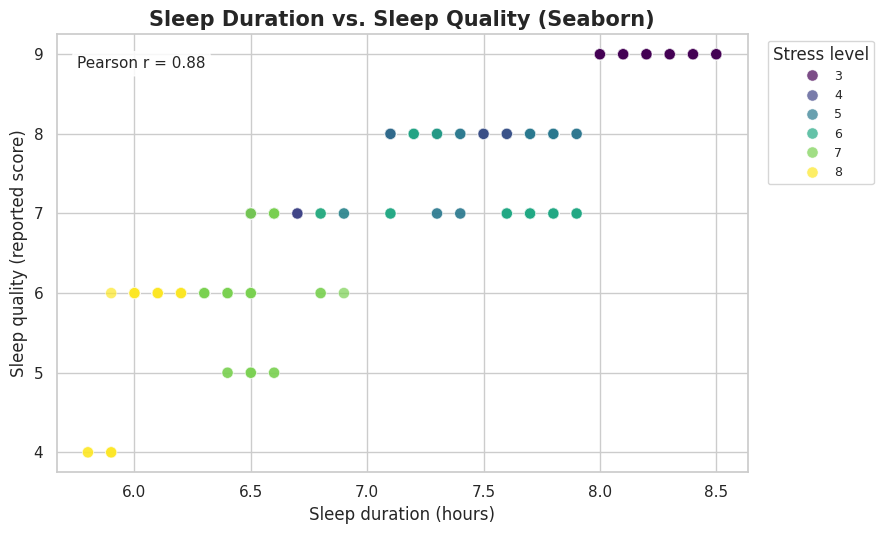

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=clean, x="sleep_duration", y="quality_of_sleep",
                hue="stress_level", palette="viridis", hue_norm=(clean["stress_level"].min(), clean["stress_level"].max()),
                s=65, alpha=0.7, edgecolor="white", linewidth=0.5,
                legend="brief", ax=ax)
ax.set_title("Sleep Duration vs. Sleep Quality (Seaborn)", fontsize=15, fontweight="bold")
ax.set_xlabel("Sleep duration (hours)", fontsize=12)
ax.set_ylabel("Sleep quality (reported score)", fontsize=12)
ax.legend(title="Stress level", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.annotate(f"Pearson r = {correlation:.2f}", xy=(0.03, 0.95),
            xycoords="axes fraction", va="top", fontsize=11,
            bbox=dict(boxstyle="round", fc="white", alpha=0.85))
plt.tight_layout()
plt.show()

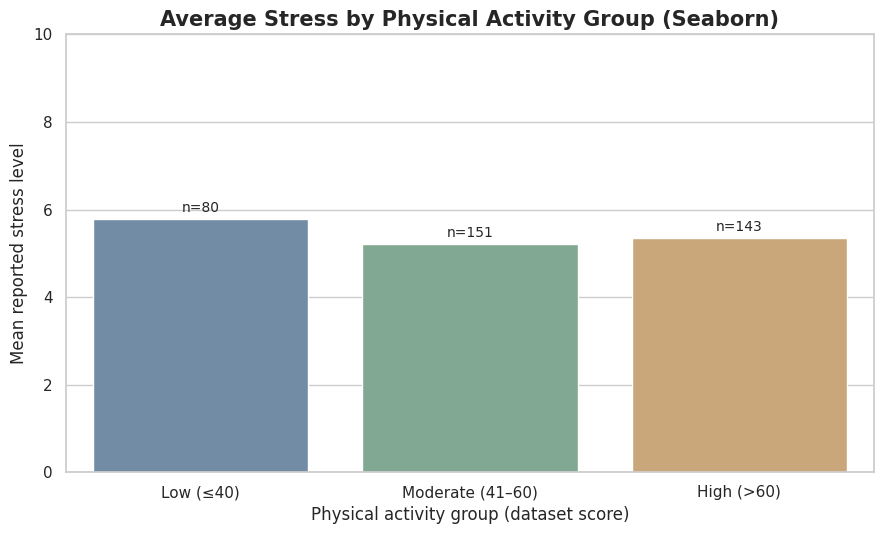

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=activity_summary, x="activity_group", y="mean_stress",
            hue="activity_group", palette=colors, dodge=False,
            legend=False, errorbar=None, ax=ax)
ax.set_title("Average Stress by Physical Activity Group (Seaborn)", fontsize=15, fontweight="bold")
ax.set_xlabel("Physical activity group (dataset score)", fontsize=12)
ax.set_ylabel("Mean reported stress level", fontsize=12)
ax.set_ylim(0, max(10, activity_summary["mean_stress"].max() * 1.2))
for bar, count in zip(ax.patches, activity_summary["count"]):
    ax.annotate(f"n={count}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

# Part 3: Matplotlib vs. Seaborn

Matplotlib provides direct control over plotting elements. In the scatterplot, I manually created the colorbar and styled the marker edges; in the bar chart, I used `ax.bar()` and annotated each bar. This gives precise control but requires more code.

Seaborn offers a higher level interface that works naturally with pandas DataFrames. Its `scatterplot()` can map a variable to color using `hue`, while `barplot()` handles categorical displays with concise syntax. I still used Matplotlib functions to adjust titles, labels, legends, and annotations. I think Seaborn is convenient for statistical visualizations, while Matplotlib is useful for detailed customization.

# Conclusion

This assignment provided an opportunity to explore the relationships between sleep patterns, physical activity, stress levels, and overall wellbeing while applying essential techniques in data exploration, data wrangling, and visualization using Python. The Sleep Health and Lifestyle Dataset was analyzed using pandas, NumPy, Matplotlib, and Seaborn, with the primary objective of identifying meaningful patterns in lifestyle related variables and comparing the visualization capabilities of Matplotlib and Seaborn.

The analysis began with data exploration, where the dataset's structure, dimensions, variable types, and observations were examined using pandas. Descriptive statistics, including the mean, median, standard deviation, minimum, maximum, and quartiles, were calculated to better understand the distribution of numerical variables. Missing values were also examined to identify potential data quality issues. This initial exploration helped establish an understanding of the dataset and determine which variables would be most useful for further analysis.

Next, data wrangling and preparations were performed to organize the dataset for visualization. This involved examining relevant variables, addressing missing values, and grouping physical activity levels into meaningful categories. Physical activity was classified into low, moderate, and high activity groups to make comparisons between activity levels and reported stress easier to interpret. These transformations demonstrated how raw data can be organized into a more suitable format for statistical analysis and visualization.

The first major finding was a strong positive relationship between sleep duration and reported sleep quality, with a Pearson correlation coefficient of r = 0.88. This shows that individuals reporting longer sleep durations generally also reported higher sleep quality. The strength of this correlation suggests a substantial linear association between the two variables within the dataset. However, this relationship does not necessarily indicate that increasing sleep duration directly causes improvements in sleep quality.

The second analysis examined the relationship between physical activity and stress levels. Individuals in the moderate physical activity group (41–60) reported the lowest average stress level of 5.22, based on 151 observations. In comparison, individuals in the low physical activity group (≤40) reported the highest average stress level of 5.78, based on 80 observations. These results suggest that individuals engaging in moderate physical activity may experience lower reported stress levels than those with lower activity levels. The differences were relatively small, and the results do not establish a causal relationship.

A central component of this assignment involved creating and comparing visualizations using Matplotlib and Seaborn. Two visualizations were first developed using Matplotlib, incorporating multiple customization properties, including plot titles, axis labels, colors, figure dimensions, font sizes, and other formatting elements. These customizations improved readability and helped communicate the relationships between variables more effectively. The same visualizations were then recreated using Seaborn to compare the two libraries while maintaining consistent underlying data.

This comparison demonstrated several important differences between the visualization libraries. Matplotlib offered greater flexibility and detailed control over individual plot elements, making it useful for highly customized visualizations. In contrast, Seaborn simplified the process of producing statistical graphics by providing convenient plotting functions and attractive default formatting. Although both libraries successfully represented the same relationships, Seaborn generally required less manual styling, while Matplotlib allowed more precise customization. Using both libraries reinforced the importance of selecting visualization tools based on the analytical objectives and desired presentation.
